# ADPTSK: a softmin that does not underflow, and the role of K

This notebook follows, one step at a time, the classifier of

> "An adaptive double-parameter softmin based Takagi-Sugeno-Kang fuzzy system for
> high-dimensional data", *Fuzzy Sets and Systems*, 2025, doi:10.1016/j.fss.2025.109582.

on Colon, one of the datasets of the article. ADPTSK computes the firing strength of a
rule with a softmin that has two adaptive parameters, and uses a Gaussian membership
function bounded below by $e^{-K}$. The notebook is a short version of the script
`examples/reproductions/adptsk_2025.py`, which runs two datasets with ten folds repeated
three times; here one repetition on one dataset runs in a few minutes.

1. settings and reproducibility;
2. the data;
3. one fold with the defaults;
4. what the fitted model looks like;
5. the effect of K over ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import ADPTSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 4

# Table 3 of the article, Colon: mean test accuracy in percent, by K.
ARTICLE = {0.2: 83.02, 0.6: 83.97, 1.0: 82.46, 1.5: 80.56, 2.0: 77.30}

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Colon is a gene-expression dataset: 62 tissue samples, 2000 genes, two classes. OpenML
stores it as a sparse matrix.

In [3]:
bunch = fetch_openml(data_id=1432, as_frame=False, parser="liac-arff")
data = bunch.data.toarray() if hasattr(bunch.data, "toarray") else bunch.data
features = np.asarray(data, dtype=np.float32)
labels = np.unique(bunch.target, return_inverse=True)[1]

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

62 samples, 2000 features
samples per class: [40, 22]


The first of ten folds is followed in detail. The article scales the inputs to [0, 1],
with the range of the training part. A test part has six or seven samples.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 55 samples, test: 7 samples


## 3. One fold with the defaults

Three rules with centres at 0, 0.5 and 1 and spreads of one, consequents starting at
zero, Adam on the whole training set for 200 iterations. The learning rate is 0.001 above
1000 features. These are the defaults of `ADPTSKClassifier`, with K = 1.

In [5]:
model = ADPTSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"learning rate chosen: {model.learning_rate_}")
print(f"training accuracy: {100 * model.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")

learning rate chosen: 0.001
training accuracy: 100.0%
test accuracy: 85.7%


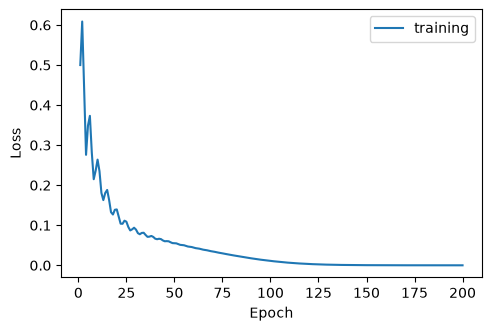

In [6]:
model.plot_history()
plt.show()

## 4. What the fitted model looks like

With 2000 features, a product of membership degrees would underflow and every rule would
get the same weight. The softmin of ADPTSK keeps the weights of the rules distinct:

In [7]:
report = model.firing_diagnostics(x_train)
print(f"samples with the same weight on every rule: {100 * report['uniform_fraction']:.0f}%")
print(f"mean weight of each rule: {np.round(report['mean_firing'], 3).tolist()}")
print(f"effective number of rules per sample: {report['effective_rules']:.2f} of {report['n_rules']}")

samples with the same weight on every rule: 0%
mean weight of each rule: [0.3, 0.403, 0.297]
effective number of rules per sample: 2.96 of 3


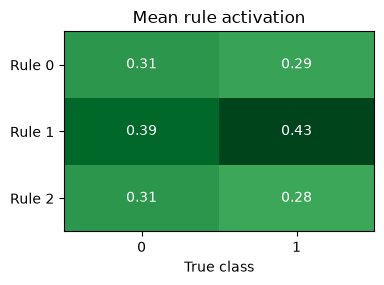

In [8]:
fig, ax = plt.subplots(figsize=(4, 2.6))
model.plot_rule_activation(x_train, y_train, ax=ax)
plt.show()

The confusion matrix and the margins, on the training part and on the seven test samples:

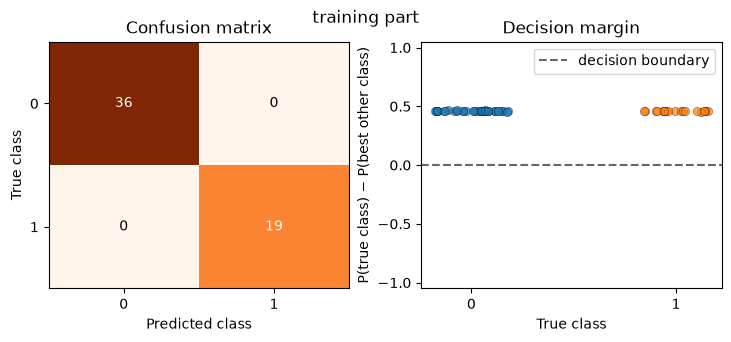

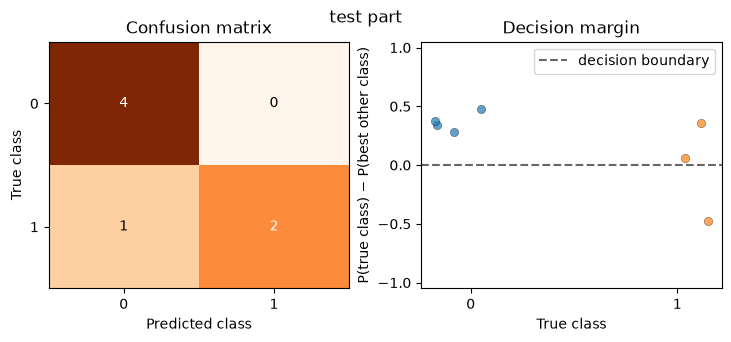

In [9]:
model.plot_diagnostics(x_train, y_train)
plt.suptitle("training part", y=1.02)
plt.show()

model.plot_diagnostics(x_test, y_test)
plt.suptitle("test part", y=1.02)
plt.show()

A summary of the model and of its training, in one call:

In [10]:
print(model.summary())

ADPTSKClassifier
  task               classification, 2 classes
  features           2000 seen in fit, 2000 used by the model
  rules              3 (rule base: coco)
  fuzzy sets         3 per feature, GaussianPiMF
  firing strength    ADPSoftminRuleLayer
  defuzzifier        SumBasedDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         24006 trainable (12000 antecedent, 12006 consequent)
Training (full batch)
  phase     epochs   rate  loss first -> last  accuracy
  training     200  0.001    0.5000 -> 0.0000    1.0000


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [11]:
print(model.explain(x_test[0]))

Prediction: 1
Output, the sum of the contributions of the 3 rules: 0: +0.13, 1: +0.87
Rule 1, weight 0.40: contributes 0: -1.31, 1: +1.72
    IF x377 is medium AND x1221 is medium AND x1231 is medium AND ... (1997 more)
Rule 0, weight 0.33: contributes 0: +0.70, 1: -0.38
    IF x377 is low AND x1221 is low AND x1231 is low AND ... (1997 more)
Rule 2, weight 0.27: contributes 0: +0.74, 1: -0.47
    IF x377 is high AND x1221 is high AND x1231 is high AND ... (1997 more)


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [12]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.96, median 0.97
test part:     min 0.97, median 0.98


## 5. The effect of K

The lower bound of the membership function is $e^{-K}$: a small K keeps every degree
close to one, a large K lets a single feature pull the firing strength of a rule down.
The article studies ten values of K and finds that the accuracy falls for K above one on
Colon. Five of them here, over the ten folds:

In [13]:
results = {k: [] for k in ARTICLE}

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])
    for k in ARTICLE:
        fitted = ADPTSKClassifier(k=k, random_state=SEED).fit(a_train, labels[train])
        results[k].append(100 * fitted.score(a_test, labels[test]))

print(f"{'K':>4s} {'article':>8s} {'highFIS':>8s} {'std':>6s}")
for k, scores in results.items():
    print(f"{k:4.1f} {ARTICLE[k]:8.2f} {np.mean(scores):8.2f} {np.std(scores):6.2f}")

   K  article  highFIS    std
 0.2    83.02    90.71   9.96
 0.6    83.97    87.38   9.04
 1.0    82.46    80.71   9.55
 1.5    80.56    72.38  10.82
 2.0    77.30    75.71  11.11


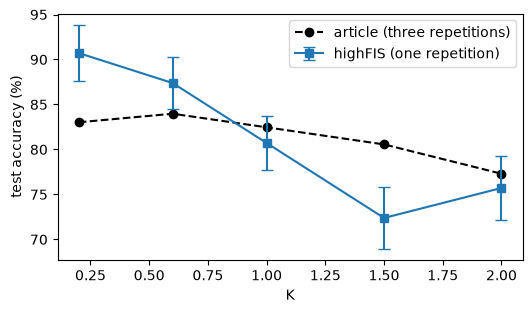

In [14]:
ks = list(ARTICLE)
means = np.array([np.mean(results[k]) for k in ks])
errors = np.array([np.std(results[k]) / np.sqrt(FOLDS) for k in ks])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ks, [ARTICLE[k] for k in ks], "o--", color="black", label="article (three repetitions)")
ax.errorbar(ks, means, yerr=errors, fmt="s-", capsize=4, label="highFIS (one repetition)")
ax.set_xlabel("K")
ax.set_ylabel("test accuracy (%)")
ax.legend()
plt.show()

The bars are the standard error of the mean over the ten folds. With 62 samples, one
test sample is 1.6 points of the cross-validated accuracy, so one repetition only shows
the trend. The script repeats the ten folds three times, as the article does, and also
runs Leukemia.